# 04 — Prepare Toronto SOLWEIG inputs with real terrain

## Purpose

This notebook creates the final SOLWEIG-ready raster inputs for the
**2 km × 2 km U of T pilot** using:

- Toronto-enriched building heights from Notebook 03;
- a real terrain DEM;
- VoxCity canopy height.

The workflow directly constructs:

- `dem.tif` — real terrain elevation;
- `dsm.tif` — real terrain + building height;
- `cdsm.tif` — canopy height.

All rasters are aligned on the same **5 m EPSG:32617** grid.

This notebook replaces the earlier two-step 04 + 04b workflow.

**Kernel:** Python 3.12 - VoxCity

## 1. Imports and project paths

In [1]:
from pathlib import Path
import math
import time

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
import requests

from PIL import Image
from rasterio.transform import from_bounds
from rasterio.warp import (
    calculate_default_transform,
    reproject,
    Resampling,
)

from voxcity.generator import load_voxcity

HERE = Path.cwd().resolve()

if HERE.name == "notebooks_toronto_v02":
    PROJECT_ROOT = HERE.parent
elif (HERE / "notebooks_toronto_v02").exists():
    PROJECT_ROOT = HERE
else:
    PROJECT_ROOT = Path(
        "/scratch/project_2010417/paper3/heat-conditioned-accessibility"
    )

TORONTO_DATA = PROJECT_ROOT / "data" / "toronto"
TORONTO_RAW = TORONTO_DATA / "raw"
TORONTO_INTERIM = TORONTO_DATA / "interim"

ENRICHED_DIR = TORONTO_INTERIM / "voxcity_enriched"

SOLWEIG_DIR = (
    TORONTO_INTERIM
    / "solweig"
    / "UOFT_PILOT"
)

TERRAIN_CACHE = (
    TORONTO_RAW
    / "terrain_tiles"
    / "UOFT_PILOT"
)

SOLWEIG_DIR.mkdir(parents=True, exist_ok=True)
TERRAIN_CACHE.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("SOLWEIG output:", SOLWEIG_DIR)

Project root: /scratch/project_2010417/paper3/heat-conditioned-accessibility
SOLWEIG output: /scratch/project_2010417/paper3/heat-conditioned-accessibility/data/toronto/interim/solweig/UOFT_PILOT


## 2. Load the enriched VoxCity pilot

In [2]:
enriched_pickle = (
    ENRICHED_DIR
    / "UOFT_PILOT_voxcity_enriched.pkl"
)

if not enriched_pickle.exists():
    raise FileNotFoundError(
        f"Missing enriched VoxCity file: {enriched_pickle}"
    )

vox = load_voxcity(
    enriched_pickle,
    trusted=True,
)

building_height = np.asarray(
    vox.buildings.heights,
    dtype=np.float32,
)

canopy_height = np.asarray(
    vox.tree_canopy.top,
    dtype=np.float32,
)

print("Building grid:", building_height.shape)
print("Canopy grid :", canopy_height.shape)

if building_height.shape != canopy_height.shape:
    raise RuntimeError(
        "Building and canopy grids have different shapes."
    )

Building grid: (408, 408)
Canopy grid : (408, 408)


## 3. Clean building and canopy arrays

Building height is treated as height above local ground.

Canopy is retained as a canopy-height surface for CDSM.

In [3]:
building_height = np.nan_to_num(
    building_height,
    nan=0.0,
    posinf=0.0,
    neginf=0.0,
)

canopy_height = np.nan_to_num(
    canopy_height,
    nan=0.0,
    posinf=0.0,
    neginf=0.0,
)

building_height[building_height < 0] = 0
canopy_height[canopy_height < 0] = 0

print(
    "Building-height max:",
    float(building_height.max()),
    "m",
)

print(
    "Canopy-height max:",
    float(canopy_height.max()),
    "m",
)

Building-height max: 116.81999969482422 m
Canopy-height max: 13.978205680847168 m


## 4. Recover VoxCity geographic bounds

These bounds define the pilot rectangle before reprojection to UTM.

In [4]:
try:
    minlon, minlat, maxlon, maxlat = (
        vox.voxels.meta.bounds
    )
except Exception as exc:
    raise RuntimeError(
        "Could not read VoxCity bounds from vox.voxels.meta.bounds."
    ) from exc

print("Bounds:")
print(minlon, minlat, maxlon, maxlat)

Bounds:
-79.40864362272377 43.65453519234437 -79.38336793360907 43.67288422832106


## 5. Define the final 5 m UTM grid

The final model grid is created once and used for DEM, DSM, and CDSM.

In [5]:
SRC_CRS = "EPSG:4326"
DST_CRS = "EPSG:32617"
TARGET_RESOLUTION_M = 5

src_height, src_width = building_height.shape

src_transform = from_bounds(
    minlon,
    minlat,
    maxlon,
    maxlat,
    src_width,
    src_height,
)

(
    dst_transform,
    dst_width,
    dst_height,
) = calculate_default_transform(
    SRC_CRS,
    DST_CRS,
    src_width,
    src_height,
    minlon,
    minlat,
    maxlon,
    maxlat,
    resolution=TARGET_RESOLUTION_M,
)

target_shape = (
    dst_height,
    dst_width,
)

print("Target CRS:", DST_CRS)
print("Target size:", target_shape)
print("Target resolution:", TARGET_RESOLUTION_M, "m")

Target CRS: EPSG:32617
Target size: (416, 416)
Target resolution: 5 m


## 6. Reproject building and canopy heights to the final grid

In [6]:
def reproject_model_surface(
    array,
    resampling=Resampling.nearest,
):
    destination = np.zeros(
        target_shape,
        dtype=np.float32,
    )

    source = np.flipud(
        array
    ).astype(
        np.float32
    )

    reproject(
        source=source,
        destination=destination,
        src_transform=src_transform,
        src_crs=SRC_CRS,
        dst_transform=dst_transform,
        dst_crs=DST_CRS,
        resampling=resampling,
    )

    return destination


building_height_5m = reproject_model_surface(
    building_height,
    Resampling.nearest,
)

canopy_height_5m = reproject_model_surface(
    canopy_height,
    Resampling.nearest,
)

print("Building layer reprojected.")
print("Canopy layer reprojected.")

Building layer reprojected.
Canopy layer reprojected.


## 7. Configure the terrain source

Terrain is downloaded from the AWS Open Data Terrain Tiles archive
using Terrarium encoding.

Terrarium elevation formula:

`elevation = R × 256 + G + B / 256 − 32768`

Zoom level 15 is used, then the terrain is resampled to the exact 5 m
modelling grid.

In [7]:
TERRAIN_ZOOM = 15
TILE_SIZE = 256

TERRAIN_URL = (
    "https://s3.amazonaws.com/"
    "elevation-tiles-prod/terrarium/"
    "{z}/{x}/{y}.png"
)

print("Terrain zoom:", TERRAIN_ZOOM)

Terrain zoom: 15


## 8. Terrain-tile helper functions

In [8]:
def lonlat_to_tile(lon, lat, zoom):

    n = 2 ** zoom

    x = int(
        math.floor(
            (lon + 180.0)
            / 360.0
            * n
        )
    )

    lat_rad = math.radians(lat)

    y = int(
        math.floor(
            (
                1.0
                - math.asinh(
                    math.tan(lat_rad)
                )
                / math.pi
            )
            / 2.0
            * n
        )
    )

    return x, y


def tile_bounds_mercator(x, y, zoom):

    origin = 20037508.342789244
    world = 2 * origin
    n = 2 ** zoom
    tile_span = world / n

    left = -origin + x * tile_span
    right = left + tile_span

    top = origin - y * tile_span
    bottom = top - tile_span

    return left, bottom, right, top


def decode_terrarium(path):

    image = Image.open(
        path
    ).convert("RGB")

    rgb = np.asarray(
        image,
        dtype=np.float32,
    )

    elevation = (
        rgb[:, :, 0] * 256.0
        + rgb[:, :, 1]
        + rgb[:, :, 2] / 256.0
        - 32768.0
    )

    return elevation.astype(
        np.float32
    )

## 9. Determine terrain tiles required for the pilot

In [9]:
west = minlon
south = minlat
east = maxlon
north = maxlat

x_min, y_max = lonlat_to_tile(
    west,
    south,
    TERRAIN_ZOOM,
)

x_max, y_min = lonlat_to_tile(
    east,
    north,
    TERRAIN_ZOOM,
)

BUFFER_TILES = 1

x_values = range(
    x_min - BUFFER_TILES,
    x_max + BUFFER_TILES + 1,
)

y_values = range(
    y_min - BUFFER_TILES,
    y_max + BUFFER_TILES + 1,
)

tile_list = [
    (x, y)
    for y in y_values
    for x in x_values
]

print(
    "Terrain tiles required:",
    len(tile_list),
)

Terrain tiles required: 25


## 10. Download and cache terrain tiles

In [10]:
session = requests.Session()

session.headers.update(
    {
        "User-Agent": (
            "heat-conditioned-accessibility "
            "Toronto terrain workflow"
        )
    }
)

tile_paths = {}

for index, (x, y) in enumerate(
    tile_list,
    start=1,
):

    tile_path = (
        TERRAIN_CACHE
        / f"z{TERRAIN_ZOOM}_x{x}_y{y}.png"
    )

    if not tile_path.exists():

        url = TERRAIN_URL.format(
            z=TERRAIN_ZOOM,
            x=x,
            y=y,
        )

        success = False

        for attempt in range(1, 4):

            try:
                response = session.get(
                    url,
                    timeout=60,
                )

                response.raise_for_status()

                tile_path.write_bytes(
                    response.content
                )

                success = True
                break

            except Exception as exc:

                print(
                    f"Attempt {attempt} failed "
                    f"for tile {x}/{y}: {exc}"
                )

                if attempt < 3:
                    time.sleep(
                        5 * attempt
                    )

        if not success:
            raise RuntimeError(
                f"Could not download terrain tile {x}/{y}"
            )

    tile_paths[(x, y)] = tile_path

    print(
        f"{index:>3}/{len(tile_list)}",
        tile_path.name,
    )

print("✓ Terrain tiles ready.")

  1/25 z15_x9155_y11955.png
  2/25 z15_x9156_y11955.png
  3/25 z15_x9157_y11955.png
  4/25 z15_x9158_y11955.png
  5/25 z15_x9159_y11955.png
  6/25 z15_x9155_y11956.png
  7/25 z15_x9156_y11956.png
  8/25 z15_x9157_y11956.png
  9/25 z15_x9158_y11956.png
 10/25 z15_x9159_y11956.png
 11/25 z15_x9155_y11957.png
 12/25 z15_x9156_y11957.png
 13/25 z15_x9157_y11957.png
 14/25 z15_x9158_y11957.png
 15/25 z15_x9159_y11957.png
 16/25 z15_x9155_y11958.png
 17/25 z15_x9156_y11958.png
 18/25 z15_x9157_y11958.png
 19/25 z15_x9158_y11958.png
 20/25 z15_x9159_y11958.png
 21/25 z15_x9155_y11959.png
 22/25 z15_x9156_y11959.png
 23/25 z15_x9157_y11959.png
 24/25 z15_x9158_y11959.png
 25/25 z15_x9159_y11959.png
✓ Terrain tiles ready.


## 11. Mosaic the terrain tiles

In [11]:
unique_x = sorted(
    set(x for x, y in tile_list)
)

unique_y = sorted(
    set(y for x, y in tile_list)
)

mosaic = np.zeros(
    (
        len(unique_y) * TILE_SIZE,
        len(unique_x) * TILE_SIZE,
    ),
    dtype=np.float32,
)

x_index = {
    x: i
    for i, x in enumerate(unique_x)
}

y_index = {
    y: i
    for i, y in enumerate(unique_y)
}

for x, y in tile_list:

    tile_dem = decode_terrarium(
        tile_paths[(x, y)]
    )

    row0 = y_index[y] * TILE_SIZE
    col0 = x_index[x] * TILE_SIZE

    mosaic[
        row0:row0 + TILE_SIZE,
        col0:col0 + TILE_SIZE,
    ] = tile_dem

print("Terrain mosaic shape:", mosaic.shape)
print(
    "Terrain mosaic range:",
    float(np.nanmin(mosaic)),
    "to",
    float(np.nanmax(mosaic)),
    "m",
)

Terrain mosaic shape: (1280, 1280)
Terrain mosaic range: 74.6796875 to 158.45703125 m


## 12. Build the terrain mosaic transform

In [12]:
left, _, _, top = tile_bounds_mercator(
    unique_x[0],
    unique_y[0],
    TERRAIN_ZOOM,
)

_, bottom, right, _ = tile_bounds_mercator(
    unique_x[-1],
    unique_y[-1],
    TERRAIN_ZOOM,
)

mosaic_transform = from_bounds(
    left,
    bottom,
    right,
    top,
    mosaic.shape[1],
    mosaic.shape[0],
)

print("Terrain mosaic CRS: EPSG:3857")

Terrain mosaic CRS: EPSG:3857


## 13. Reproject terrain directly onto the final 5 m UTM grid

This is the critical alignment step: the DEM is not allowed to define a
separate raster grid.

In [13]:
dem_5m = np.full(
    target_shape,
    np.nan,
    dtype=np.float32,
)

reproject(
    source=mosaic,
    destination=dem_5m,
    src_transform=mosaic_transform,
    src_crs="EPSG:3857",
    dst_transform=dst_transform,
    dst_crs=DST_CRS,
    dst_nodata=np.nan,
    resampling=Resampling.bilinear,
)

if np.isnan(dem_5m).any():
    raise RuntimeError(
        "Terrain reprojection produced missing cells."
    )

terrain_relief = (
    float(np.nanmax(dem_5m))
    - float(np.nanmin(dem_5m))
)

print(
    "DEM range:",
    float(np.nanmin(dem_5m)),
    "to",
    float(np.nanmax(dem_5m)),
    "m",
)

print(
    "Terrain relief:",
    terrain_relief,
    "m",
)

DEM range: 88.73968505859375 to 119.85032653808594 m
Terrain relief: 31.110641479492188 m


## 14. Build the final DSM and CDSM

The final surfaces are:

- `DEM = real terrain`
- `DSM = DEM + building height`
- `CDSM = canopy height`

Building and canopy heights remain relative to local ground.

In [14]:
dsm_5m = (
    dem_5m
    + building_height_5m
).astype(
    np.float32
)

cdsm_5m = (
    canopy_height_5m
).astype(
    np.float32
)

print(
    "Final DSM range:",
    float(np.nanmin(dsm_5m)),
    "to",
    float(np.nanmax(dsm_5m)),
    "m",
)

print(
    "Final CDSM range:",
    float(np.nanmin(cdsm_5m)),
    "to",
    float(np.nanmax(cdsm_5m)),
    "m",
)

Final DSM range: 88.73968505859375 to 216.92864990234375 m
Final CDSM range: 0.0 to 13.978205680847168 m


## 15. Visualize the final terrain, building, canopy, and DSM layers

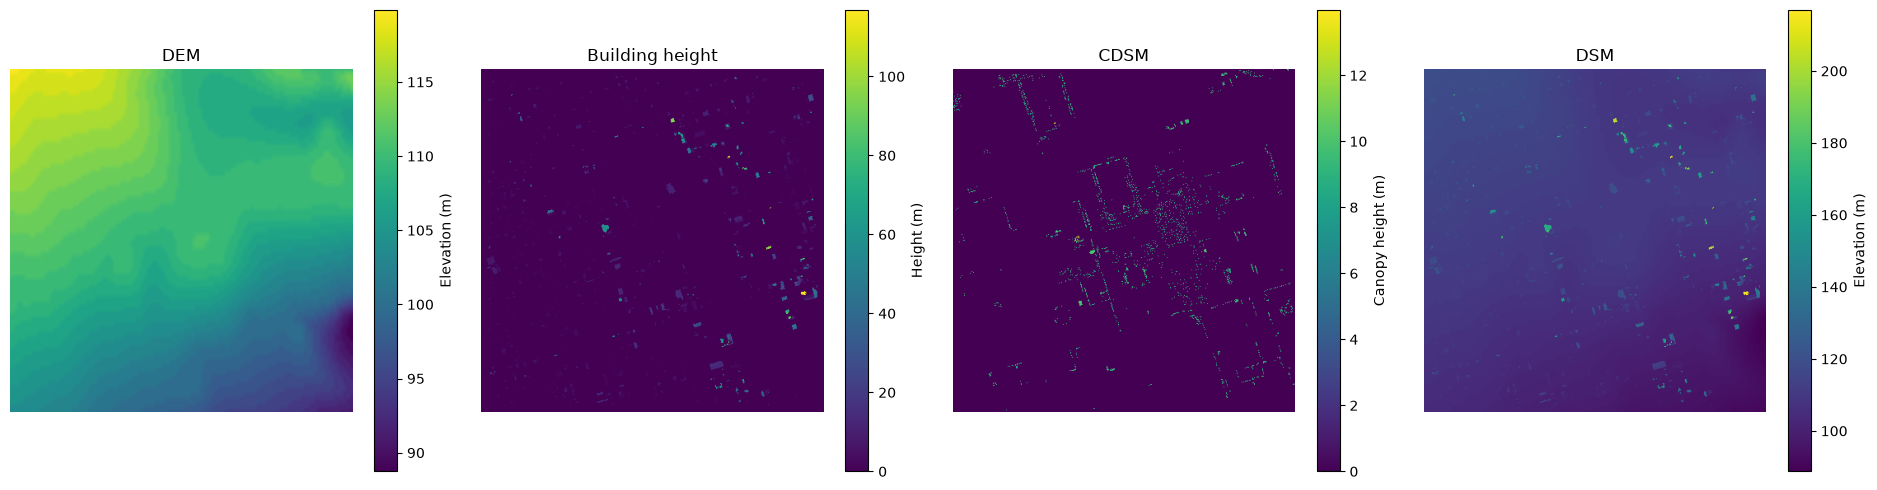

In [15]:
fig, axes = plt.subplots(
    1,
    4,
    figsize=(19, 5),
)

layers = [
    (
        dem_5m,
        "DEM",
        "Elevation (m)",
    ),
    (
        building_height_5m,
        "Building height",
        "Height (m)",
    ),
    (
        cdsm_5m,
        "CDSM",
        "Canopy height (m)",
    ),
    (
        dsm_5m,
        "DSM",
        "Elevation (m)",
    ),
]

for ax, (
    array,
    title,
    label,
) in zip(axes, layers):

    image = ax.imshow(
        array,
        origin="upper",
    )

    ax.set_title(title)
    ax.set_axis_off()

    plt.colorbar(
        image,
        ax=ax,
        label=label,
    )

plt.tight_layout()
plt.show()

## 16. Save the final SOLWEIG rasters

In [16]:
raster_profile = {
    "driver": "GTiff",
    "height": dst_height,
    "width": dst_width,
    "count": 1,
    "dtype": "float32",
    "crs": DST_CRS,
    "transform": dst_transform,
    "compress": "lzw",
}

dsm_path = SOLWEIG_DIR / "dsm.tif"
cdsm_path = SOLWEIG_DIR / "cdsm.tif"
dem_path = SOLWEIG_DIR / "dem.tif"

def write_surface(path, array):

    with rasterio.open(
        path,
        "w",
        **raster_profile,
    ) as dst:

        dst.write(
            array.astype(np.float32),
            1,
        )


write_surface(
    dem_path,
    dem_5m,
)

write_surface(
    dsm_path,
    dsm_5m,
)

write_surface(
    cdsm_path,
    cdsm_5m,
)

print("Saved:")
print("-", dem_path)
print("-", dsm_path)
print("-", cdsm_path)

Saved:
- /scratch/project_2010417/paper3/heat-conditioned-accessibility/data/toronto/interim/solweig/UOFT_PILOT/dem.tif
- /scratch/project_2010417/paper3/heat-conditioned-accessibility/data/toronto/interim/solweig/UOFT_PILOT/dsm.tif
- /scratch/project_2010417/paper3/heat-conditioned-accessibility/data/toronto/interim/solweig/UOFT_PILOT/cdsm.tif


## 17. Validate exact raster alignment

In [17]:
validation_rows = []
metadata = []

for path in [
    dem_path,
    dsm_path,
    cdsm_path,
]:

    with rasterio.open(path) as src:

        array = src.read(1)

        validation_rows.append(
            {
                "file": path.name,
                "crs": str(src.crs),
                "width": src.width,
                "height": src.height,
                "res_x": src.res[0],
                "res_y": src.res[1],
                "min": float(np.nanmin(array)),
                "mean": float(np.nanmean(array)),
                "max": float(np.nanmax(array)),
            }
        )

        metadata.append(
            (
                src.shape,
                src.crs,
                src.transform,
                src.bounds,
            )
        )

display(
    pd.DataFrame(
        validation_rows
    )
)

if not all(
    item == metadata[0]
    for item in metadata[1:]
):
    raise RuntimeError(
        "DEM, DSM, and CDSM are not perfectly aligned."
    )

print(
    "✓ DEM, DSM, and CDSM are perfectly aligned."
)

,file,crs,width,height,res_x,res_y,min,mean,max
0,dem.tif,EPSG:32617,416,416,5.0,5.0,88.739685,107.207680,119.850327
1,dsm.tif,EPSG:32617,416,416,5.0,5.0,88.739685,107.678024,216.928650
2,cdsm.tif,EPSG:32617,416,416,5.0,5.0,0.000000,0.126081,13.978206


✓ DEM, DSM, and CDSM are perfectly aligned.


## 18. Final summary

In [18]:
summary = {
    "model": "UOFT_PILOT",
    "target_crs": DST_CRS,
    "target_resolution_m": TARGET_RESOLUTION_M,
    "raster_width_cells": dst_width,
    "raster_height_cells": dst_height,
    "terrain_min_m": float(np.nanmin(dem_5m)),
    "terrain_mean_m": float(np.nanmean(dem_5m)),
    "terrain_max_m": float(np.nanmax(dem_5m)),
    "terrain_relief_m": float(terrain_relief),
    "building_height_max_m": float(
        np.nanmax(building_height_5m)
    ),
    "canopy_max_m": float(
        np.nanmax(cdsm_5m)
    ),
    "final_dsm_max_m": float(
        np.nanmax(dsm_5m)
    ),
}

for key, value in summary.items():
    print(
        f"{key}: {value}"
    )

model: UOFT_PILOT
target_crs: EPSG:32617
target_resolution_m: 5
raster_width_cells: 416
raster_height_cells: 416
terrain_min_m: 88.73968505859375
terrain_mean_m: 107.20767974853516
terrain_max_m: 119.85032653808594
terrain_relief_m: 31.110641479492188
building_height_max_m: 116.81999969482422
canopy_max_m: 13.978205680847168
final_dsm_max_m: 216.92864990234375


## Interpretation and next step

This notebook now provides a clean final preparation stage:

**Toronto building heights + real terrain + VoxCity canopy
→ aligned 5 m DEM / DSM / CDSM**

There is no intermediate flat DEM in the final workflow.

The next notebook can therefore proceed directly to:

**`05_toronto_weather_and_solweig.ipynb`**

For Toronto v2, the main thermal surface should be generated at a
**common hot-afternoon timestep** rather than relying primarily on
cell-wise daily-maximum UTCI.